# Estimator interfaces across seven econometric families

A common `.fit(solver=...)` interface covers linear, likelihood and nonlinear
criteria. This tour fits each smooth model using both TRU and ARC, uses QPB for
simplex synthetic control, and demonstrates robust and clustered inference.
All simulated designs contain feature columns only; each regression constructor
adds its own intercept. These are small worked examples rather than a timing study.

In [1]:
import os
# Notebook-process settings; importing the library never changes these.
os.environ.setdefault("OMP_CANCELLATION", "TRUE")
os.environ.setdefault("OMP_PROC_BIND", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

%matplotlib inline
thread_limit = threadpool_limits(limits=1)
rng = np.random.default_rng(1003)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                      "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 9)
pd.set_option("display.max_columns", 10)
pd.options.display.float_format = "{:.5g}".format

In [2]:
from scipy.special import expit
from galahad_econometrics import OLS, Ridge, Logit, Poisson, IVGMM, ExponentialNLS, SyntheticControl

n, p = 2000, 3
X = rng.normal(size=(n, p))
D = np.column_stack([np.ones(n), X])
beta = np.array([.2, .5, -.3, .2])
eta = D @ beta
clusters = np.repeat(np.arange(40), n // 40)
group_shock = .5 * rng.normal(size=40)
y_linear = eta + group_shock[clusters] + (.2 + .2*np.abs(X[:, 0])) * rng.normal(size=n)
exposure = rng.uniform(.7, 1.6, n)
offset = np.log(exposure)

Z = rng.normal(size=(n, 5))
u, v = rng.normal(size=n), rng.normal(size=(n, p))
X_iv = Z[:, :p] + v
X_iv[:, 0] += .7*u
D_iv = np.column_stack([np.ones(n), X_iv])
y_iv = D_iv @ beta + u

models = {
    "OLS": OLS(X, y_linear),
    "Ridge": Ridge(X, y_linear, penalty=.05),
    "Logit": Logit(X, rng.binomial(1, expit(eta))),
    "Poisson": Poisson(X, rng.poisson(np.exp(eta + offset)), offset=offset),
    "IV/GMM": IVGMM(X_iv, y_iv, Z),
    "Exponential NLS": ExponentialNLS(X, np.exp(eta) + .15*rng.normal(size=n)),
}
truth_means = {"OLS": eta, "Ridge": eta, "Logit": expit(eta),
               "Poisson": np.exp(eta + offset), "IV/GMM": D_iv @ beta,
               "Exponential NLS": np.exp(eta)}

## Exchange TRU and ARC without changing the model

The table compares optimizers within the same sample and criterion. The maximum
coefficient discrepancy is a numerical comparison; statistical recovery from the
DGP is shown separately below. Ridge explicitly returns point estimates only.

For IV/GMM, the plotted model mean is the structural component $X\beta$. It is generally different from the observational conditional mean $E[y\mid X]$ because the regressors are endogenous.

In [3]:
fits, rows = {}, []
for name, model in models.items():
    cov_type = "HC1" if model.supports_inference else None
    a = model.fit(solver="tru", cov_type=cov_type)
    b = model.fit(solver="arc", cov_type=cov_type)
    assert a.success and b.success
    assert abs(a.optimization.fun - b.optimization.fun) < 1e-10
    fits[name] = a
    rows.append({"family": name, "TRU status": a.optimization.status,
                 "ARC status": b.optimization.status,
                 "max coefficient difference": np.max(np.abs(a.params-b.params)),
                 "inference": cov_type or "not implemented"})

donors = rng.normal(size=(120, 8))
treated = donors @ np.r_[.2, .3, .5, np.zeros(5)] + .02*rng.normal(size=120)
scm = SyntheticControl(donors, treated).fit()
assert scm.success
rows.append({"family": "Synthetic control", "TRU status": "QPB used",
             "ARC status": "QPB used", "max coefficient difference": np.nan,
             "inference": "not implemented"})
display(pd.DataFrame(rows).set_index("family"))
print("SCM native status:", scm.optimization.status,
      "simplex gap:", scm.optimization.optimality,
      "feasibility:", scm.optimization.feasibility)

,TRU status,ARC status,max coefficient difference,inference
family,,,,
OLS,0,0,4.9105e-13,HC1
Ridge,0,0,2.416e-10,not implemented
Logit,0,0,1.0718e-08,HC1
Poisson,0,0,8.4293e-12,HC1
IV/GMM,0,0,3.1586e-13,HC1
Exponential NLS,0,0,6.1062e-16,HC1
Synthetic control,QPB used,QPB used,NaN,not implemented


SCM native status: 0 simplex gap: 6.304185222894693e-10 feasibility: 2.220446049250313e-16


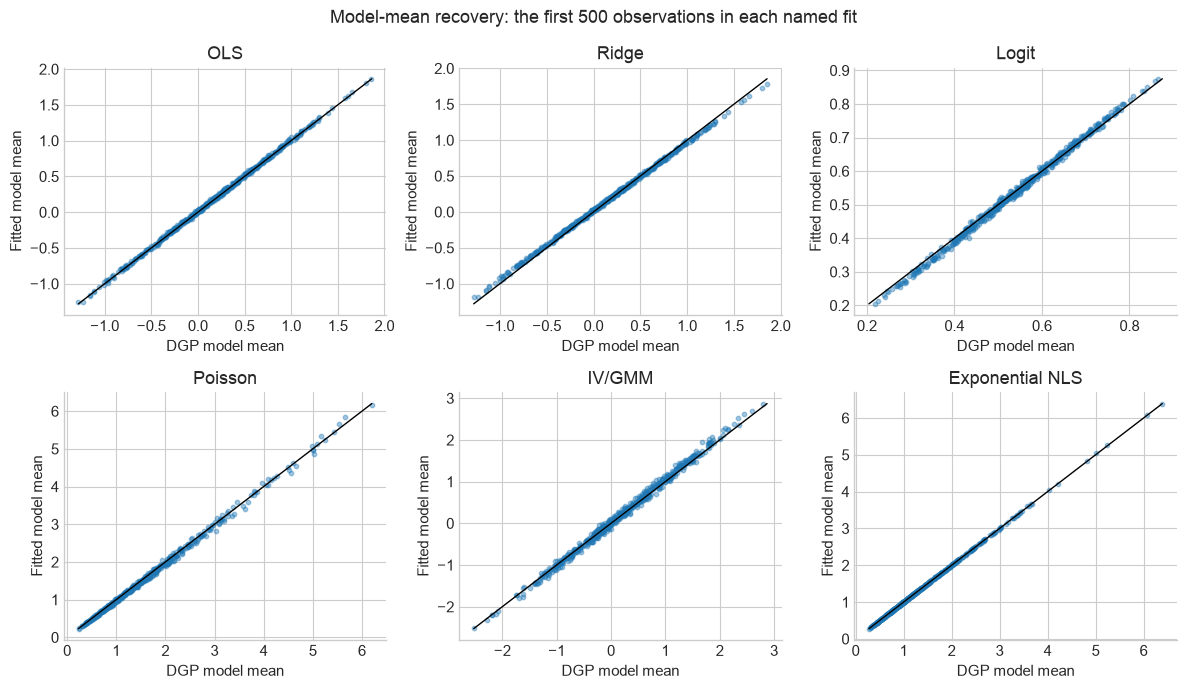

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (name, fit) in zip(axes.flat, fits.items()):
    truth, estimate = truth_means[name][:500], fit.fitted_values[:500]
    ax.scatter(truth, estimate, s=10, alpha=.4)
    lo, hi = min(truth.min(), estimate.min()), max(truth.max(), estimate.max())
    ax.plot([lo, hi], [lo, hi], color="black", linewidth=1)
    ax.set(title=name, xlabel="DGP model mean", ylabel="Fitted model mean")
fig.suptitle("Model-mean recovery: the first 500 observations in each named fit")
fig.tight_layout()
plt.show()

## Clustered inference

The linear response contains a common shock within each of 40 groups. The point
estimate is identical under HC1 and one-way CR1; the covariance differs. CR1 uses
`G/(G-1) * (n-1)/(n-p)` and this prototype reports normal-approximation intervals.
A clustered standard error need not be larger for every parameter.

In [5]:
hc1 = fits["OLS"]
cr1 = models["OLS"].fit(solver="arc", cov_type="cluster", clusters=clusters)
assert np.max(np.abs(hc1.params - cr1.params)) < 1e-7
assert cr1.cov_info["n_clusters"] == 40
pd.DataFrame({"truth": beta, "estimate": hc1.params, "HC1 SE": hc1.bse, "CR1 SE": cr1.bse},
             index=models["OLS"].param_names)

,truth,estimate,HC1 SE,CR1 SE
intercept,0.2,0.21209,0.014337,0.083622
x1,0.5,0.50623,0.016188,0.016801
x2,-0.3,-0.30018,0.013915,0.015896
x3,0.2,0.18672,0.014361,0.01363


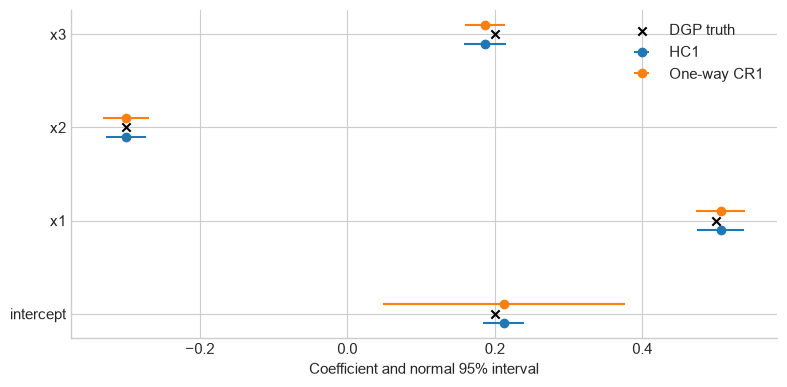

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
positions = np.arange(p + 1)
for shift, fit, label in [(-.1, hc1, "HC1"), (.1, cr1, "One-way CR1")]:
    ax.errorbar(fit.params, positions+shift, xerr=1.96*fit.bse, fmt="o", label=label)
ax.scatter(beta, positions, color="black", marker="x", label="DGP truth", zorder=3)
ax.set_yticks(positions, models["OLS"].param_names)
ax.set_xlabel("Coefficient and normal 95% interval")
ax.legend()
fig.tight_layout()
plt.show()

## Inspect and predict

The fit retains native status and solver controls in `fit.optimization.info`.
New Poisson predictions require the new offsets if an offset was used in training.
Fixed-weight IV/GMM takes all regressors and instruments explicitly; it does not
infer endogenous/exogenous roles or automatically perform a second weight update.
The later notebooks develop regularization, IV/GMM, NLS and SCM in more detail.

In [7]:
predicted_counts = fits["Poisson"].predict(X[:5], offset=offset[:5])
assert np.isfinite(predicted_counts).all()
pd.DataFrame({"offset": offset[:5], "fitted mean": predicted_counts})

,offset,fitted mean
0,0.38055,0.83472
1,0.38371,1.9402
2,0.33571,3.2619
3,-0.33768,0.82039
4,-0.098799,0.3742
